## Agentowa symulacja Ofiara-Drapieżca
Emilia Tkaczewska 292795

In [38]:
import sys
sys.path.append("src")
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prey_predator_sim.species import Prey, Predator
from prey_predator_sim.population import Population

In [39]:
# funkcje pomocnicze
def run_sim(seed, p_death=P_DEATH, p_reproduce=P_REPRODUCE):
    random.seed(seed)
    pop = Population(START, p_death=p_death, p_reproduce=p_reproduce)
    for _ in range(STEPS):
        pop.natural_selection()
    return pop

def summarize(runs, name):
    prey = []
    pred = []

    for p in runs:
        prey.append(p.n[Prey])
        pred.append(p.n[Predator])

    prey = np.array(prey)
    pred = np.array(pred)

    return {
        "scenariusz": name,
        "% wymarcia ofiar": 100 * np.mean(prey == 0),
        "% wymarcia drapieżców": 100 * np.mean(pred == 0),
        "ofiary: śr.": prey.mean(),
        "ofiary: std": prey.std(ddof=1),
        "drapieżcy: śr.": pred.mean(),
        "drapieżcy: std": pred.std(ddof=1),
    }

## Test uruchomieniowy
Start {Prey: 30, Predator: 30}, 150 kroków

In [40]:
# parametry
START = {Prey: 30, Predator: 30} 
STEPS = 150
N_RUNS = 10
P_DEATH = 0.2
P_REPRODUCE = 0.6

Końcowa liczebność: {'Prey': 47, 'Predator': 83}


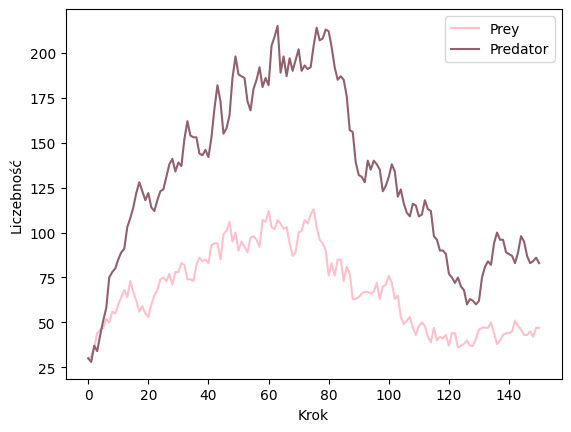

In [41]:
pop = run_sim(seed=0)
print("Końcowa liczebność:", {s.__name__: v for s, v in pop.n.items()})
pop.plot_history()

## Powtarzalność

In [42]:
p1 = run_sim(seed=42)
p2 = run_sim(seed=42)
print("Identyczne przebiegi:", p1.history == p2.history)

Identyczne przebiegi: True


## Eksperyment bazowy

In [43]:
base_runs = [run_sim(seed=s) for s in range(N_RUNS)]
res = summarize(base_runs, "bazowy")

for k, v in res.items():
    if k != "scenariusz":
        print(f"{k:22s}: {v:.2f}")

% wymarcia ofiar      : 20.00
% wymarcia drapieżców : 20.00
ofiary: śr.           : 44.10
ofiary: std           : 45.40
drapieżcy: śr.        : 79.70
drapieżcy: std        : 80.37


## Analiza wrażliwości

dla:  
`p_reproduce`: {0.55, 0.60, 0.65}  
`p_death`: {0.1, 0.2, 0.3}

In [44]:
LIMIT = 5000

scenarios = [
    ("p_reproduce=0.55", P_DEATH, 0.55),
    ("p_reproduce=0.60", P_DEATH, 0.60),
    ("p_reproduce=0.65", P_DEATH, 0.65),
    ("p_death=0.10", 0.10, P_REPRODUCE),
    ("p_death=0.20", 0.20, P_REPRODUCE),
    ("p_death=0.30", 0.30, P_REPRODUCE),
]

rows = []

for name, pd_v, pr_v in scenarios:
    runs = []

    for s in range(N_RUNS):
        random.seed(s)
        pop = Population(START, p_death=pd_v, p_reproduce=pr_v)

        for _ in range(STEPS):
            pop.natural_selection()
            if sum(pop.n.values()) > LIMIT:
                break

        runs.append(pop)

    rows.append(summarize(runs, name))

df = pd.DataFrame(rows).set_index("scenariusz").round(2)
df

,% wymarcia ofiar,% wymarcia drapieżców,ofiary: śr.,ofiary: std,drapieżcy: śr.,drapieżcy: std
scenariusz,,,,,,
p_reproduce=0.55,100.0,100.0,0.0,0.00,0.0,0.00
p_reproduce=0.60,20.0,20.0,44.1,45.40,79.7,80.37
p_reproduce=0.65,0.0,0.0,1776.2,54.35,3354.5,59.10
p_death=0.10,0.0,0.0,1717.5,48.18,3415.9,34.47
p_death=0.20,20.0,20.0,44.1,45.40,79.7,80.37
p_death=0.30,80.0,90.0,1270.2,2679.77,5.9,18.66


- Silna wrażliwość na niewielkie zmiany w `p_reproduce` i `p_death`
- Zbyt niski `p_reproduce` (0.55) prowadzi do całkowitego wymarcia populacji
- Wysoki `p_reproduce` (0.65) lub niski `p_death` (0.10) powoduje gwałtowny wzrost liczebności populacji i 0% wymarć

## Histogram atrybutu 'p_reproduce'

Liczebność końcowa: {'Prey': 30, 'Predator': 30}


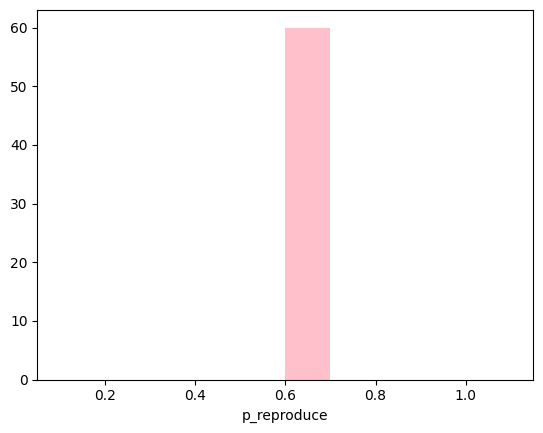

In [45]:
pop_hist = run_sim(seed=6)
print("Liczebność końcowa:", {s.__name__: v for s, v in pop_hist.n.items()})
pop_hist.plot_histogram("p_reproduce")

Gdy w populacji przeżywają osobniki, wartości `p_reproduce` skupiają się w jednym słupku, ponieważ potomstwo dziedziczy cechę bez mutacji.